# Project 04: Supply Chain & Inventory Risk Optimisation

**Tools:** Python, Pandas, NumPy, Matplotlib  
**Dataset:** DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS (about 180,519 order-line records)

## How to use
1. Open this notebook in Google Colab.
2. Select **Runtime → Run all**.
3. Wait while the notebook downloads the public dataset and runs the analysis.
4. At the end, download the ZIP file containing the scorecards, charts and CSV outputs.

**Data transparency:** The original DataCo dataset contains order, product and shipping information. It does not provide complete supplier master records or historical warehouse inventory snapshots. Therefore, this notebook creates clearly labelled *synthetic* supplier assignments and inventory snapshots for demonstration. Supplier-level reliability and stockout results are estimates based on those assumptions, not observed supplier/inventory facts.

**Dataset attribution:** Constante, Fabian; Silva, Fernando; Pereira, António (2019), *DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS*, Mendeley Data, version 5, DOI: 10.17632/8gx2fvg2k6.5. CC BY 4.0.


## 1. Import libraries and download the dataset

This cell installs/imports the standard libraries and downloads the original CSV directly from the public Mendeley Data file endpoint. No manual Kaggle upload is needed. The CSV is approximately 91.5 MB, so the first run may take a few minutes.

In [4]:

import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import warnings

warnings.filterwarnings("ignore")
np.random.seed(42)

DATA_FILE = "/content/DataCoSupplyChainDataset.csv"

urls = [
    "https://raw.githubusercontent.com/ashishpatel26/DataCo-SMART-SUPPLY-CHAIN-FOR-BIG-DATA-ANALYSIS/main/DataCoSupplyChainDataset.csv",
    "https://raw.githubusercontent.com/McGill-MMA-EnterpriseAnalytics/DataCo_Supply_Chain/main/data/raw/DataCoSupplyChainDataset.csv",
    "https://data.mendeley.com/public-files/datasets/8gx2fvg2k6/files/72784be5-36d3-44fe-b75d-0edbf1999f65/file_downloaded"
]

if not os.path.exists(DATA_FILE):

    success = False

    for url in urls:
        try:
            print("Downloading dataset...")

            response = requests.get(
                url,
                stream=True,
                timeout=180,
                headers={"User-Agent": "Mozilla/5.0"}
            )

            response.raise_for_status()

            temp = DATA_FILE + ".part"
            size = 0

            with open(temp, "wb") as f:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        size += len(chunk)

            if size < 10_000_000:
                os.remove(temp)
                raise ValueError("Incomplete dataset download")

            os.replace(temp, DATA_FILE)
            success = True

            print("Dataset downloaded successfully!")
            print("Size:", round(size / (1024 * 1024), 2), "MB")
            break

        except Exception as e:
            print("Source failed:", str(e)[:200])

    if not success:
        raise Exception(
            "All download links failed. Try again or upload the CSV manually."
        )

df = pd.read_csv(
    DATA_FILE,
    encoding="ISO-8859-1",
    low_memory=False
)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())


Dataset downloaded successfully!
Size: 91.29 MB
Dataset loaded successfully!
Rows: 180519
Columns: 53


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 2. Understand and clean the data

We standardise column names, remove duplicate rows, convert dates and numeric fields, and remove unnecessary personal/customer-identifying columns. This keeps the analysis focused on orders, products and deliveries.

In [5]:
df.columns = df.columns.str.strip().str.lower()

private_columns = [
    "customer email", "customer password", "customer fname",
    "customer lname", "customer street", "customer zipcode",
    "product image", "product description"
]
df = df.drop(columns=[c for c in private_columns if c in df.columns], errors="ignore")
df = df.drop_duplicates()

required = [
    "product card id", "order item quantity",
    "days for shipping (real)", "days for shipment (scheduled)",
    "order date (dateorders)"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Dataset is missing required columns: {missing}")

for col in [
    "product card id", "order item quantity",
    "days for shipping (real)", "days for shipment (scheduled)"
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["order date (dateorders)"] = pd.to_datetime(
    df["order date (dateorders)"], errors="coerce"
)

df = df.dropna(subset=[
    "product card id", "order item quantity",
    "order date (dateorders)"
])
df = df[df["order item quantity"] > 0].copy()

print("Rows after cleaning:", len(df))
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values in key fields:")
display(df[required].isna().sum().to_frame("missing_count"))


Rows after cleaning: 180519
Duplicate rows remaining: 0
Missing values in key fields:


,missing_count
product card id,0
order item quantity,0
days for shipping (real),0
days for shipment (scheduled),0
order date (dateorders),0


## 3. Create product master and validate keys

The product master is built from distinct product IDs in the source data. We check duplicate and missing product IDs before joining the synthetic supplier mapping.

In [6]:
product_name_col = "product name" if "product name" in df.columns else None
category_col = "category name" if "category name" in df.columns else None
price_col = "product price" if "product price" in df.columns else None

products = pd.DataFrame({
    "product_id": df["product card id"],
    "product_name": df[product_name_col] if product_name_col else df["product card id"].astype(str),
    "category": df[category_col] if category_col else "Unknown",
    "unit_price": pd.to_numeric(df[price_col], errors="coerce") if price_col else np.nan
}).drop_duplicates("product_id").reset_index(drop=True)

print("Unique products:", products["product_id"].nunique())
print("Missing product keys:", products["product_id"].isna().sum())
print("Duplicate product keys:", products["product_id"].duplicated().sum())
display(products.head())


Unique products: 118
Missing product keys: 0
Duplicate product keys: 0


,product_id,product_name,category,unit_price
0,1360,Smart watch,Sporting Goods,327.750000
1,365,Perfect Fitness Perfect Rip Deck,Cleats,59.990002
2,627,Under Armour Girls' Toddler Spine Surge Runni,Shop By Sport,39.990002
3,502,Nike Men's Dri-FIT Victory Golf Polo,Women's Apparel,50.000000
4,278,Under Armour Men's Compression EV SL Slide,Electronics,44.990002


## 4. Create a documented synthetic supplier table

The source dataset does not identify procurement suppliers. For the assignment's supplier analysis, we assign each product to one simulated supplier and generate an assumed procurement lead time. These records are synthetic and must be described as assumptions in the report.

In [7]:
supplier_ids = [f"SUP-{i:03d}" for i in range(1, 16)]
rng = np.random.default_rng(42)

product_supplier = pd.DataFrame({
    "product_id": products["product_id"],
    "supplier_id": rng.choice(supplier_ids, size=len(products), replace=True)
})

suppliers = pd.DataFrame({
    "supplier_id": supplier_ids,
    "supplier_name": [f"Simulated Supplier {i}" for i in range(1, 16)],
    "assumed_procurement_lead_time_days": rng.integers(3, 16, size=15),
    "data_type": "synthetic assumption"
})

print("Unmatched supplier keys:",
      (~product_supplier["supplier_id"].isin(suppliers["supplier_id"])).sum())
print("Products without supplier mapping:",
      product_supplier["product_id"].isna().sum())
display(suppliers)


Unmatched supplier keys: 0
Products without supplier mapping: 0


,supplier_id,supplier_name,assumed_procurement_lead_time_days,data_type
0,SUP-001,Simulated Supplier 1,6,synthetic assumption
1,SUP-002,Simulated Supplier 2,4,synthetic assumption
2,SUP-003,Simulated Supplier 3,8,synthetic assumption
3,SUP-004,Simulated Supplier 4,11,synthetic assumption
4,SUP-005,Simulated Supplier 5,11,synthetic assumption
5,SUP-006,Simulated Supplier 6,9,synthetic assumption
6,SUP-007,Simulated Supplier 7,14,synthetic assumption
7,SUP-008,Simulated Supplier 8,10,synthetic assumption
8,SUP-009,Simulated Supplier 9,4,synthetic assumption
9,SUP-010,Simulated Supplier 10,12,synthetic assumption


In [19]:
df

,type,days for shipping (real),days for shipment (scheduled),benefit per order,sales per customer,delivery status,late_delivery_risk,category id,category name,customer city,...,product category id,product name,product price,product status,shipping date (dateorders),shipping mode,actual_lead_time,scheduled_lead_time,late_delivery,order_day
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,73,Smart watch,327.750000,0,2/3/2018 22:56,Standard Class,3,4,0,2018-01-31
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,73,Smart watch,327.750000,0,1/18/2018 12:27,Standard Class,5,4,1,2018-01-13
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,73,Smart watch,327.750000,0,1/17/2018 12:06,Standard Class,4,4,0,2018-01-13
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,73,Smart watch,327.750000,0,1/16/2018 11:45,Standard Class,3,4,0,2018-01-13
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,73,Smart watch,327.750000,0,1/15/2018 11:24,Standard Class,2,4,0,2018-01-13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class,4,4,0,2016-01-16
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class,3,2,1,2016-01-16
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class,5,4,1,2016-01-15
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,45,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class,3,4,0,2016-01-15


## 5. Measure shipment lead time and late deliveries

The dataset provides actual shipping days and scheduled shipping days. We calculate delivery delay, average/median lead time and late-delivery rate by shipping mode.

In [8]:
df["actual_lead_time"] = df["days for shipping (real)"]
df["scheduled_lead_time"] = df["days for shipment (scheduled)"]
df["late_delivery"] = (
    df["actual_lead_time"] > df["scheduled_lead_time"]
).astype(int)

shipping_mode_col = "shipping mode" if "shipping mode" in df.columns else None
if shipping_mode_col:
    shipping_summary = df.groupby(shipping_mode_col).agg(
        shipments=("actual_lead_time", "count"),
        average_lead_time=("actual_lead_time", "mean"),
        median_lead_time=("actual_lead_time", "median"),
        lead_time_std=("actual_lead_time", "std"),
        late_delivery_rate=("late_delivery", "mean")
    ).reset_index()
else:
    shipping_summary = df[["actual_lead_time", "late_delivery"]].describe()

if shipping_mode_col:
    shipping_summary["late_delivery_rate_pct"] = (
        shipping_summary["late_delivery_rate"] * 100
    ).round(2)
display(shipping_summary)


,shipping mode,shipments,average_lead_time,median_lead_time,lead_time_std,late_delivery_rate,late_delivery_rate_pct
0,First Class,27814,2.000000,2.0,0.000000,1.000000,100.00
1,Same Day,9737,0.478279,0.0,0.499554,0.478279,47.83
2,Second Class,35216,3.990828,4.0,1.415900,0.797308,79.73
3,Standard Class,107752,3.995907,4.0,1.417266,0.397682,39.77


## 6. Supplier scorecard (estimated)

We join the real shipment rows to the synthetic product-to-supplier mapping. The resulting supplier scorecard is an *estimated proxy*: it assigns each product's observed shipment outcomes to its simulated supplier.

In [9]:
supplier_shipments = df.merge(
    product_supplier,
    left_on="product card id",
    right_on="product_id",
    how="left",
    validate="many_to_one"
)

supplier_metrics = supplier_shipments.groupby("supplier_id").agg(
    shipment_count=("late_delivery", "count"),
    average_shipping_days=("actual_lead_time", "mean"),
    late_delivery_rate=("late_delivery", "mean"),
    shipping_time_std=("actual_lead_time", "std")
).reset_index()

supplier_scorecard = suppliers.merge(
    supplier_metrics, on="supplier_id", how="left"
)
supplier_scorecard["reliability_score_pct"] = (
    100 * (1 - supplier_scorecard["late_delivery_rate"])
).round(2)

display(supplier_scorecard.sort_values(
    "reliability_score_pct", na_position="last"
))


,supplier_id,supplier_name,assumed_procurement_lead_time_days,data_type,shipment_count,average_shipping_days,late_delivery_rate,shipping_time_std,reliability_score_pct
13,SUP-014,Simulated Supplier 14,10,synthetic assumption,791,3.577750,0.609355,1.675198,39.06
0,SUP-001,Simulated Supplier 1,6,synthetic assumption,721,3.578363,0.599168,1.626099,40.08
5,SUP-006,Simulated Supplier 6,9,synthetic assumption,1205,3.606639,0.593361,1.610170,40.66
4,SUP-005,Simulated Supplier 5,11,synthetic assumption,1144,3.493007,0.587413,1.634049,41.26
3,SUP-004,Simulated Supplier 4,11,synthetic assumption,649,3.528505,0.587057,1.645102,41.29
12,SUP-013,Simulated Supplier 13,10,synthetic assumption,2135,3.423888,0.583607,1.616947,41.64
9,SUP-010,Simulated Supplier 10,12,synthetic assumption,11131,3.499775,0.576947,1.630922,42.31
14,SUP-015,Simulated Supplier 15,4,synthetic assumption,1113,3.642408,0.576819,1.604759,42.32
8,SUP-009,Simulated Supplier 9,4,synthetic assumption,16816,3.480019,0.573680,1.624509,42.63
2,SUP-003,Simulated Supplier 3,8,synthetic assumption,20692,3.493186,0.573217,1.627747,42.68


## 7. Calculate daily demand and variability

Daily demand is the sum of units ordered for each product on each calendar day. We calculate average daily demand and its standard deviation for every product.

In [10]:
df["order_day"] = df["order date (dateorders)"].dt.floor("D")
daily = df.groupby(["product card id", "order_day"])["order item quantity"].sum()

all_days = pd.date_range(
    df["order_day"].min(), df["order_day"].max(), freq="D"
)
daily_demand = daily.unstack(fill_value=0).reindex(
    columns=all_days, fill_value=0
)

demand_summary = pd.DataFrame({
    "product_id": daily_demand.index,
    "average_daily_demand": daily_demand.mean(axis=1).values,
    "demand_std": daily_demand.std(axis=1).fillna(0).values
}).reset_index(drop=True)

demand_summary["coefficient_of_variation"] = (
    demand_summary["demand_std"] /
    demand_summary["average_daily_demand"].replace(0, np.nan)
).fillna(0)

display(demand_summary.head())


,product_id,average_daily_demand,demand_std,coefficient_of_variation
0,19,0.056788,0.267157,4.704460
1,24,0.204969,1.056844,5.156120
2,35,0.057675,0.281538,4.881442
3,37,0.692990,1.605324,2.316517
4,44,0.833185,1.855968,2.227557


## 8. ABC and XYZ inventory segmentation

**ABC:** ranks products by sales value (or quantity if sales is unavailable): A represents the first 80% cumulative contribution, B the next 15%, and C the remainder.

**XYZ:** groups demand variability using coefficient of variation (CV): X ≤ 0.50, Y ≤ 1.00, Z > 1.00. These are illustrative thresholds.

In [11]:
if "sales" in df.columns:
    df["sales"] = pd.to_numeric(df["sales"], errors="coerce").fillna(0)
    product_value = df.groupby("product card id")["sales"].sum()
    value_basis = "sales"
else:
    product_value = df.groupby("product card id")["order item quantity"].sum()
    value_basis = "ordered quantity"

abc = product_value.sort_values(ascending=False).rename("value").reset_index()
abc = abc.rename(columns={"product card id": "product_id"})
abc["cumulative_pct"] = (
    abc["value"].cumsum() / abc["value"].sum() * 100
)
abc["ABC_class"] = np.select(
    [abc["cumulative_pct"] <= 80, abc["cumulative_pct"] <= 95],
    ["A", "B"], default="C"
)

item = products.merge(abc, on="product_id", how="left")
item = item.merge(demand_summary, on="product_id", how="left")
item["XYZ_class"] = np.select(
    [item["coefficient_of_variation"] <= 0.5,
     item["coefficient_of_variation"] <= 1.0],
    ["X", "Y"], default="Z"
)
item["ABC_XYZ"] = item["ABC_class"] + item["XYZ_class"]

print("ABC value basis:", value_basis)
display(item["ABC_XYZ"].value_counts().rename_axis("segment").to_frame("products"))


ABC value basis: sales


,products
segment,
CZ,95
BZ,14
AX,7
BX,2


## 9. Build a simulated inventory snapshot and calculate reorder points

Because the original data does not include historical on-hand inventory, we generate a clearly labelled synthetic stock snapshot. The assumed stock is between 15 and 45 days of average demand.

Safety stock uses the common proxy: **Z × demand standard deviation × √lead time**. Here Z = 1.65, approximately a 95% one-sided service factor under a normal-demand assumption.

In [12]:
item = item.merge(
    product_supplier, on="product_id", how="left", validate="one_to_one"
).merge(
    suppliers[["supplier_id", "assumed_procurement_lead_time_days"]],
    on="supplier_id", how="left", validate="many_to_one"
)

item["inventory_on_hand_simulated"] = np.where(
    item["average_daily_demand"] > 0,
    np.round(
        item["average_daily_demand"] *
        rng.uniform(15, 45, size=len(item))
    ),
    0
)

Z = 1.65
item["safety_stock"] = (
    Z * item["demand_std"] *
    np.sqrt(item["assumed_procurement_lead_time_days"])
)
item["reorder_point"] = (
    item["average_daily_demand"] *
    item["assumed_procurement_lead_time_days"] +
    item["safety_stock"]
)
item["days_of_cover"] = (
    item["inventory_on_hand_simulated"] /
    item["average_daily_demand"].replace(0, np.nan)
).fillna(0)
item["reorder_status"] = np.where(
    item["inventory_on_hand_simulated"] < item["reorder_point"],
    "REORDER", "STOCK ABOVE REORDER POINT"
)

display(item[[
    "product_id", "supplier_id", "ABC_XYZ",
    "average_daily_demand", "demand_std",
    "assumed_procurement_lead_time_days",
    "inventory_on_hand_simulated", "days_of_cover",
    "safety_stock", "reorder_point", "reorder_status"
]].head(10))


,product_id,supplier_id,ABC_XYZ,average_daily_demand,demand_std,assumed_procurement_lead_time_days,inventory_on_hand_simulated,days_of_cover,safety_stock,reorder_point,reorder_status
0,1360,SUP-002,BZ,0.316770,4.262888,4,8.0,25.254902,14.067530,15.334611,REORDER
1,365,SUP-012,AX,65.393079,27.644516,11,1041.0,15.919116,151.282701,870.606570,STOCK ABOVE REORDER POINT
2,627,SUP-010,BX,28.158829,14.044226,12,791.0,28.090657,80.273535,418.179480,STOCK ABOVE REORDER POINT
3,502,SUP-007,AX,55.861579,24.567383,14,1198.0,21.445867,151.672505,933.734617,STOCK ABOVE REORDER POINT
4,278,SUP-007,CZ,0.721384,1.645953,14,20.0,27.724477,10.161676,20.261054,REORDER
5,249,SUP-013,CZ,0.751553,1.703730,10,31.0,41.247934,8.889650,16.405178,STOCK ABOVE REORDER POINT
6,191,SUP-002,AX,32.546584,16.063410,4,717.0,22.029962,53.009252,183.195587,STOCK ABOVE REORDER POINT
7,917,SUP-011,CZ,0.825200,1.764200,10,14.0,16.965591,9.205169,17.457165,REORDER
8,828,SUP-004,CZ,0.803904,1.769001,11,19.0,23.634658,9.680733,18.523679,STOCK ABOVE REORDER POINT
9,642,SUP-002,CZ,0.823425,1.839439,4,20.0,24.288793,6.070149,9.363849,STOCK ABOVE REORDER POINT


## 10. NumPy Monte Carlo simulation

For each product, we simulate 5,000 possible demand outcomes during its assumed procurement lead time. A stockout occurs when simulated lead-time demand is greater than the simulated on-hand inventory. This produces a modelled risk probability, not an observed historical stockout rate.

In [13]:
N_SIM = 5000
stockout_risk = []
expected_lead_demand = []

for row in item.itertuples(index=False):
    mu = max(float(row.average_daily_demand), 0)
    sigma = max(float(row.demand_std), 0)
    lead = max(int(row.assumed_procurement_lead_time_days), 1)

    simulated_daily = rng.normal(
        loc=mu, scale=sigma, size=(N_SIM, lead)
    )
    simulated_daily = np.maximum(simulated_daily, 0)
    simulated_total = simulated_daily.sum(axis=1)

    stock = float(row.inventory_on_hand_simulated)
    stockout_risk.append((simulated_total > stock).mean() * 100)
    expected_lead_demand.append(simulated_total.mean())

item["simulated_stockout_probability_pct"] = stockout_risk
item["expected_lead_time_demand"] = expected_lead_demand

display(item[[
    "product_id", "inventory_on_hand_simulated",
    "expected_lead_time_demand",
    "simulated_stockout_probability_pct"
]].sort_values(
    "simulated_stockout_probability_pct", ascending=False
).head(15))


,product_id,inventory_on_hand_simulated,expected_lead_time_demand,simulated_stockout_probability_pct
89,208,0.0,1.045198,100.00
85,860,0.0,0.919969,100.00
88,226,0.0,0.799175,100.00
60,58,0.0,1.137017,99.96
21,60,0.0,0.696352,99.88
82,61,0.0,0.881322,99.82
30,1353,8.0,31.578449,99.20
31,1357,3.0,15.139433,98.90
29,1363,15.0,37.915532,96.06
18,1352,7.0,20.837045,95.10


## 11. Excess stock and replenishment scenarios

We compare current stock with two reorder policies:
- **Basic policy:** Z = 1.28 (approximately 90% one-sided service factor).
- **High-service policy:** Z = 1.96 (approximately 97.5% one-sided service factor).

The excess-stock metric is a simple screening proxy: stock above twice the reorder point. It is not a financial valuation of obsolete stock.

In [14]:
item["safety_stock_basic"] = (
    1.28 * item["demand_std"] *
    np.sqrt(item["assumed_procurement_lead_time_days"])
)
item["safety_stock_high_service"] = (
    1.96 * item["demand_std"] *
    np.sqrt(item["assumed_procurement_lead_time_days"])
)

lead_demand_mean = (
    item["average_daily_demand"] *
    item["assumed_procurement_lead_time_days"]
)
item["basic_reorder_point"] = lead_demand_mean + item["safety_stock_basic"]
item["high_service_reorder_point"] = lead_demand_mean + item["safety_stock_high_service"]

item["basic_additional_units"] = np.maximum(
    0, item["basic_reorder_point"] - item["inventory_on_hand_simulated"]
)
item["high_service_additional_units"] = np.maximum(
    0, item["high_service_reorder_point"] - item["inventory_on_hand_simulated"]
)
item["excess_inventory_proxy_units"] = np.maximum(
    0, item["inventory_on_hand_simulated"] - 2 * item["reorder_point"]
)

scenario_rows = []
for row in item.itertuples(index=False):
    mu = max(float(row.average_daily_demand), 0)
    sigma = max(float(row.demand_std), 0)
    lead = max(int(row.assumed_procurement_lead_time_days), 1)
    sims = np.maximum(
        rng.normal(mu, sigma, size=(N_SIM, lead)), 0
    ).sum(axis=1)

    scenario_rows.append({
        "product_id": row.product_id,
        "current_stockout_probability_pct":
            (sims > row.inventory_on_hand_simulated).mean() * 100,
        "basic_policy_stockout_probability_pct":
            (sims > max(row.inventory_on_hand_simulated, row.basic_reorder_point)).mean() * 100,
        "high_service_stockout_probability_pct":
            (sims > max(row.inventory_on_hand_simulated, row.high_service_reorder_point)).mean() * 100
    })

scenario_comparison = pd.DataFrame(scenario_rows)
display(scenario_comparison.mean(numeric_only=True).round(2).to_frame("average_probability_pct"))


,average_probability_pct
product_id,689.58
current_stockout_probability_pct,30.72
basic_policy_stockout_probability_pct,16.50
high_service_stockout_probability_pct,5.03


## 12. Prioritise interventions under a budget

The budget is an illustrative constraint, not a real company budget. For an approximate unit-cost proxy, we use product price when available. We rank products by stockout probability, sales/value exposure and demand variability, then allocate the assumed budget to the highest-ranked products first.

In [15]:
# Product price is used as an approximate unit-cost proxy where available.
# It is not a verified procurement cost.
if "unit_price" not in item.columns:
    item["unit_price"] = np.nan

item["unit_cost_proxy"] = pd.to_numeric(
    item["unit_price"], errors="coerce"
).fillna(0).clip(lower=0)

value_rank = item["value"].rank(pct=True).fillna(0)
variability_rank = item["coefficient_of_variation"].rank(pct=True).fillna(0)

item["priority_score"] = (
    0.50 * item["simulated_stockout_probability_pct"] +
    0.30 * value_rank * 100 +
    0.20 * variability_rank * 100
)

item["risk_category"] = np.select(
    [item["simulated_stockout_probability_pct"] >= 70,
     item["simulated_stockout_probability_pct"] >= 40],
    ["CRITICAL", "HIGH"], default="MODERATE"
)

item["recommended_action"] = np.select(
    [item["risk_category"] == "CRITICAL",
     item["risk_category"] == "HIGH",
     item["excess_inventory_proxy_units"] > 0],
    ["Expedite/replenish; verify supplier",
     "Review reorder quantity and lead time",
     "Review excess stock and transfer options"],
    default="Monitor and review periodically"
)

# Example budget = 15% of the cost proxy for all high-service replenishment needs.
total_need_cost = (
    item["high_service_additional_units"] * item["unit_cost_proxy"]
).sum()
budget = max(0, total_need_cost * 0.15)
remaining_budget = budget
item["approved_replenishment_units"] = 0.0

for idx in item.sort_values("priority_score", ascending=False).index:
    qty = float(item.loc[idx, "high_service_additional_units"])
    cost = float(item.loc[idx, "unit_cost_proxy"])
    if cost > 0 and remaining_budget > 0:
        approved = min(qty, remaining_budget / cost)
        item.loc[idx, "approved_replenishment_units"] = approved
        remaining_budget -= approved * cost

print("Illustrative replenishment budget:", round(budget, 2))
print("Unspent budget:", round(remaining_budget, 2))
display(item.sort_values("priority_score", ascending=False)[[
    "product_id", "ABC_XYZ", "simulated_stockout_probability_pct",
    "excess_inventory_proxy_units", "priority_score",
    "approved_replenishment_units", "risk_category",
    "recommended_action"
]].head(20))


Illustrative replenishment budget: 20222.57
Unspent budget: 0.0


,product_id,ABC_XYZ,simulated_stockout_probability_pct,excess_inventory_proxy_units,priority_score,approved_replenishment_units,risk_category,recommended_action
30,1353,BZ,99.20,0.0,93.583051,35.261033,CRITICAL,Expedite/replenish; verify supplier
31,1357,CZ,98.90,0.0,91.738136,18.735160,CRITICAL,Expedite/replenish; verify supplier
18,1352,BZ,95.10,0.0,91.363559,0.000000,CRITICAL,Expedite/replenish; verify supplier
29,1363,BZ,96.06,0.0,91.080847,0.000000,CRITICAL,Expedite/replenish; verify supplier
89,208,CZ,100.00,0.0,90.593220,0.000000,CRITICAL,Expedite/replenish; verify supplier
19,1349,BZ,91.02,0.0,89.747288,0.000000,CRITICAL,Expedite/replenish; verify supplier
20,1351,BZ,87.56,0.0,89.457966,0.000000,CRITICAL,Expedite/replenish; verify supplier
76,1356,BZ,89.72,0.0,88.927797,0.000000,CRITICAL,Expedite/replenish; verify supplier
49,1350,BZ,70.56,0.0,78.669831,0.000000,CRITICAL,Expedite/replenish; verify supplier
79,1362,CZ,80.86,0.0,77.209661,0.000000,CRITICAL,Expedite/replenish; verify supplier


## 13. KPI dashboard and visualisations

The dashboard summarises shipment performance, product risk and inventory segmentation. Charts are generated from the cleaned source data and the explicitly simulated inventory model.

SUPPLY CHAIN PERFORMANCE SUMMARY
---------------------------------------------
Order-line records: 180,519
Products: 118
Total ordered units: 384,079
Average actual shipping time (days): 3.5
Late delivery rate (%): 57.28
Products with simulated stockout risk >= 50%: 35
Total simulated on-hand units: 8,585
Excess inventory proxy units: 1,701


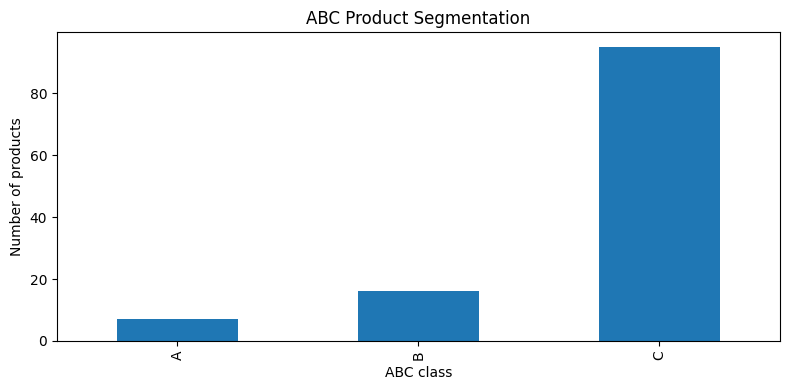

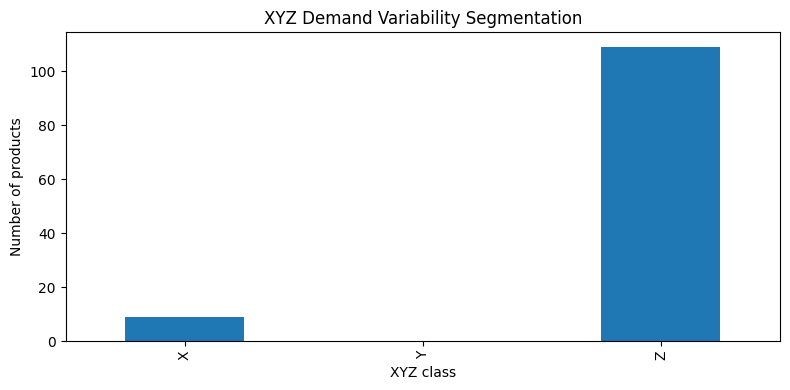

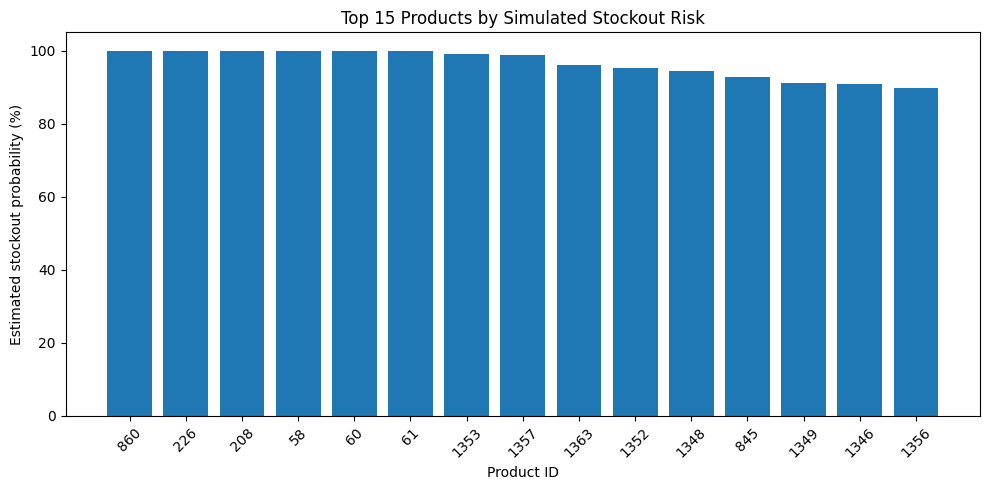

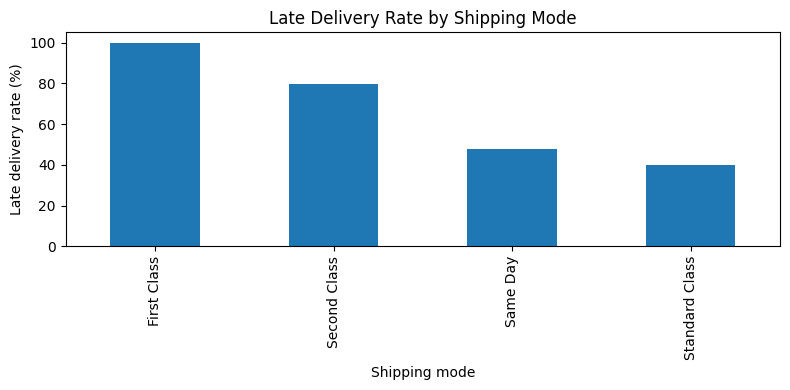

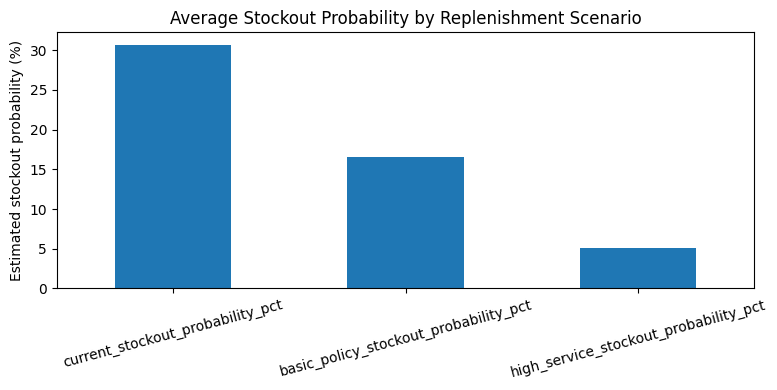

In [16]:
total_units = df["order item quantity"].sum()
late_rate = df["late_delivery"].mean() * 100
avg_ship_days = df["actual_lead_time"].mean()
high_risk_products = (item["simulated_stockout_probability_pct"] >= 50).sum()

print("SUPPLY CHAIN PERFORMANCE SUMMARY")
print("-" * 45)
print("Order-line records:", f"{len(df):,}")
print("Products:", f"{products['product_id'].nunique():,}")
print("Total ordered units:", f"{total_units:,.0f}")
print("Average actual shipping time (days):", round(avg_ship_days, 2))
print("Late delivery rate (%):", round(late_rate, 2))
print("Products with simulated stockout risk >= 50%:", int(high_risk_products))
print("Total simulated on-hand units:", f"{item['inventory_on_hand_simulated'].sum():,.0f}")
print("Excess inventory proxy units:", f"{item['excess_inventory_proxy_units'].sum():,.0f}")

plt.figure(figsize=(8, 4))
item["ABC_class"].value_counts().reindex(["A", "B", "C"]).plot(kind="bar")
plt.title("ABC Product Segmentation")
plt.xlabel("ABC class")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
item["XYZ_class"].value_counts().reindex(["X", "Y", "Z"]).plot(kind="bar")
plt.title("XYZ Demand Variability Segmentation")
plt.xlabel("XYZ class")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
top = item.nlargest(15, "simulated_stockout_probability_pct")
plt.bar(top["product_id"].astype(str), top["simulated_stockout_probability_pct"])
plt.title("Top 15 Products by Simulated Stockout Risk")
plt.xlabel("Product ID")
plt.ylabel("Estimated stockout probability (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

if shipping_mode_col:
    plot_data = df.groupby(shipping_mode_col)["late_delivery"].mean() * 100
    plt.figure(figsize=(8, 4))
    plot_data.sort_values(ascending=False).plot(kind="bar")
    plt.title("Late Delivery Rate by Shipping Mode")
    plt.xlabel("Shipping mode")
    plt.ylabel("Late delivery rate (%)")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8, 4))
scenario_comparison.set_index("product_id").mean().plot(kind="bar")
plt.title("Average Stockout Probability by Replenishment Scenario")
plt.ylabel("Estimated stockout probability (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 14. Export all project outputs into one ZIP file

This final cell saves the cleaned order data, product master, synthetic supplier data, supplier scorecard, item risk scorecard, replenishment recommendations, shipping summary, scenario comparison and charts. It then triggers a ZIP download in Google Colab.

In [17]:
# Create readable output tables
final_scorecard = item[[
    "product_id", "product_name", "category", "supplier_id",
    "ABC_class", "XYZ_class", "ABC_XYZ",
    "average_daily_demand", "demand_std",
    "assumed_procurement_lead_time_days",
    "inventory_on_hand_simulated", "days_of_cover",
    "safety_stock", "reorder_point",
    "simulated_stockout_probability_pct",
    "excess_inventory_proxy_units", "priority_score",
    "approved_replenishment_units", "risk_category",
    "recommended_action"
]].copy()

supplier_scorecard.to_csv("supplier_scorecard.csv", index=False)
products.to_csv("product_master.csv", index=False)
suppliers.to_csv("synthetic_supplier_master.csv", index=False)
final_scorecard.to_csv("inventory_risk_scorecard.csv", index=False)
scenario_comparison.to_csv("scenario_comparison.csv", index=False)
shipping_summary.to_csv("shipping_performance.csv", index=False)
item.to_csv("replenishment_recommendations.csv", index=False)

# Export a cleaned analytical dataset without customer-identifying fields
df.to_csv("cleaned_supply_chain_data.csv", index=False)

output_files = [
    "cleaned_supply_chain_data.csv",
    "product_master.csv",
    "synthetic_supplier_master.csv",
    "supplier_scorecard.csv",
    "inventory_risk_scorecard.csv",
    "replenishment_recommendations.csv",
    "shipping_performance.csv",
    "scenario_comparison.csv"
]

zip_name = "Supply_Chain_Project_Results.zip"
with zipfile.ZipFile(zip_name, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for filename in output_files:
        zf.write(filename)

print("Project complete. ZIP created:", zip_name)
print("Files included:", len(output_files))

from google.colab import files
files.download(zip_name)


Project complete. ZIP created: Supply_Chain_Project_Results.zip
Files included: 8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Conclusion and presentation notes

### What the analysis demonstrates
- Data validation and product/supplier key reconciliation.
- Shipment lead-time distribution and delivery reliability.
- Demand variability, safety-stock proxy, reorder point and days of cover.
- Monte Carlo estimates of stockout risk under demand uncertainty.
- ABC/XYZ product segmentation.
- Excess-stock screening and replenishment scenario comparison.
- Budget-constrained intervention ranking.

### Important limitations
1. DataCo contains order-line and shipping data, not a full supplier master or historical inventory ledger.
2. Supplier assignments and procurement lead times are synthetic assumptions.
3. Inventory on hand is a synthetic snapshot generated for this project.
4. Supplier reliability is a proxy derived from associated shipment outcomes.
5. Stockout probabilities are simulation estimates, not observed stockout events.
6. Product price is used only as a rough cost proxy where available; it is not verified purchase cost.
7. The 15% replenishment budget is an illustrative assumption.

### Dataset reference
Constante, F., Silva, F., & Pereira, A. (2019). *DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS* (Version 5). Mendeley Data. https://doi.org/10.17632/8gx2fvg2k6.5

**License:** CC BY 4.0. Cite the dataset authors in your submission.
